<a href="https://colab.research.google.com/github/omaralsubgh/NLP/blob/main/Lab_11_Attention_with_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention
##Omar Alsubgh | 2210002182

### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

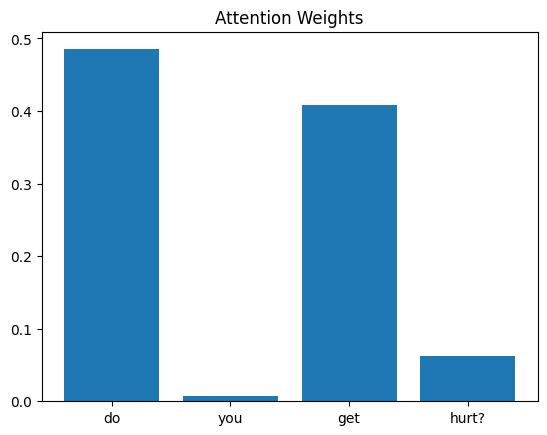

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

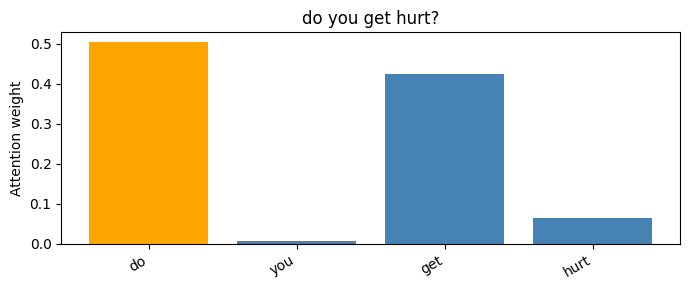

Highest attention: do (0.5036)


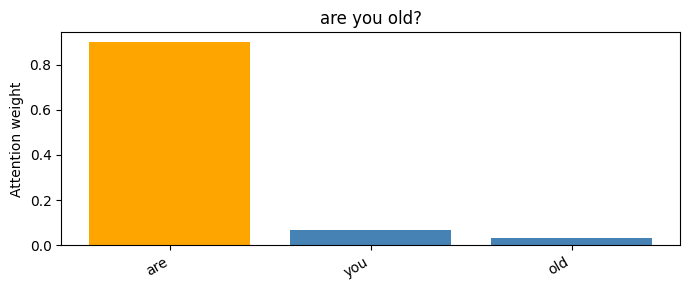

Highest attention: are (0.8977)


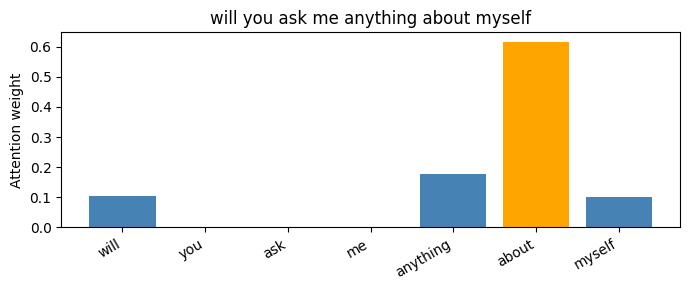

Highest attention: about (0.6164)


In [8]:
import matplotlib.pyplot as plt
import torch

def plot_attention(row):
    model.eval()

    # Remove padding so attention is calculated only over real tokens.
    token_ids = X[row][X[row] != 0]
    words = [tokenizer.index_word[int(i)] for i in token_ids]

    with torch.no_grad():
        _, weights = model(token_ids.unsqueeze(0))

    scores = weights[0].cpu().tolist()
    highest = max(range(len(scores)), key=scores.__getitem__)
    question = df.iloc[row]["question"]

    plt.figure(figsize=(7, 3))
    plt.bar(
        range(len(words)),
        scores,
        color=["orange" if i == highest else "steelblue"
               for i in range(len(words))]
    )
    plt.xticks(range(len(words)), words, rotation=30, ha="right")
    plt.ylabel("Attention weight")
    plt.title(question)
    plt.tight_layout()
    plt.show()

    print(f"Highest attention: {words[highest]} ({scores[highest]:.4f})")
    return words[highest]

# Three questions from different answer groups.
for row in [0, 14, 28]:
    plot_attention(row)

Observation: These rows ask about getting hurt, being old, and being asked about oneself. Words like hurt, old, and myself help distinguish their meanings. Compare those words with the orange bars from your run. If a general word like you gets the highest weight, the model may be using its position or the surrounding wording. The highest weight shows where the model placed the most attention; it does not prove that word was decisive.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

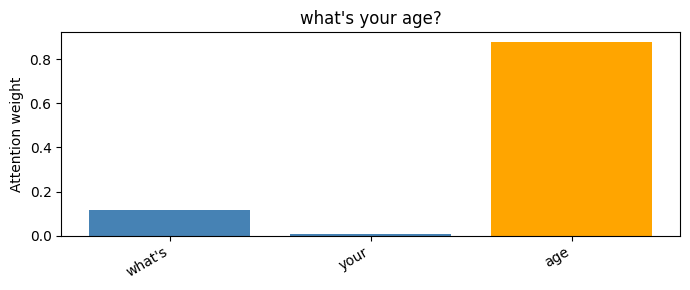

Highest attention: age (0.8792)


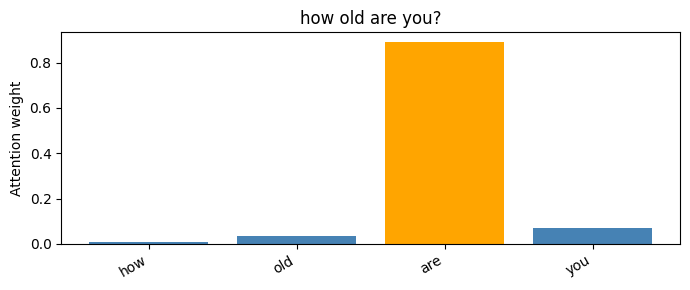

Highest attention: are (0.8896)

what's your age? → age
how old are you? → are
Same highest-attention word: False


In [9]:
first, second = 20, 24

top_first = plot_attention(first)
top_second = plot_attention(second)

print(f"\n{df.iloc[first]['question']} → {top_first}")
print(f"{df.iloc[second]['question']} → {top_second}")
print("Same highest-attention word:", top_first == top_second)

Observation: If the top words are age and old, the model is attending to different words that express the same idea. If the top words are less specific, report what the charts actually show. Attention is calculated separately for each question from the RNN’s representations, so two questions can have the same meaning and still receive different attention patterns.